<a href="https://colab.research.google.com/github/marisaoliveiracosta17/MP-knn/blob/main/Fabiana_aula02_notebook_guiado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 2 (assíncrona) — Parte A: notebook guiado

**Grandes Modelos de Linguagem · Residência em Engenharia de Software Inteligente (FACOM/UFMS)**
Prof. Bruno Nogueira · prazo: até 18/11/2026, 23h59 · atividade **individual** · cerca de 1h30

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bmnogueira-ufms/LLM-ESIA-2026/blob/main/aula02/aula02_notebook_guiado.ipynb)

Neste notebook você vai colocar a mão na massa com os conceitos da Aula 1:

| Exercício | Família / conceito | O que você vai fazer |
|---|---|---|
| 1 | Tokenização | comparar três tokenizadores em textos do **seu MVP** |
| 2 | Encoder-only | gerar embeddings com o BERTimbau, medir similaridade e treinar um classificador |
| 3 | Encoder-decoder | resumir um texto com um T5 em português |
| 4 | Decoder-only | fazer sua primeira chamada a um LLM e resolver **a mesma classificação** do exercício 2 em *zero-shot* |

As células marcadas com **✍️** pedem uma resposta curta sua. Elas vão alimentar a **ficha do caso de uso** (Parte B, em grupo).

> **Antes de começar:** *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*.

## 0. Preparação

In [1]:
!pip install -q tiktoken openai

In [2]:
import time, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import tiktoken
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", device)

dispositivo: cuda


### Seus textos

Substitua os exemplos abaixo por **5 a 10 textos reais (ou realistas) do domínio do seu MVP** — mensagens de usuários, descrições, documentos curtos. **Não use dados pessoais ou sensíveis.**

In [3]:
TEXTOS_DO_MVP = [
    "Preciso registrar que meu ex está rondando meu trabalho e enviando mensagens intimidatórias.",
    "Meu companheiro reteve meus cartões e não permite que eu use o dinheiro da casa.",
    "Ele quebrou a janela e tentou entrar enquanto eu estava com minha filha em casa.",
    "Gostaria de saber como consultar o andamento de uma medida protetiva já solicitada.",
    "Depois da separação, ele publicou fotos minhas sem autorização e continua me procurando.",
    "A pessoa descumpriu a ordem de não contato e apareceu na porta da escola da criança.",
    "Não sei quais documentos devo anexar para pedir uma medida protetiva.",
    "Recebi ameaça de morte e o agressor mencionou que guarda uma arma em casa.",
]

---
## Exercício 1 — Tokenização

Compare três tokenizadores de famílias diferentes:
- **BERTimbau** (`neuralmind/bert-base-portuguese-cased`) — encoder-only, WordPiece, treinado em português;
- **GPT-4o** (`o200k_base`, via `tiktoken`) — decoder-only proprietário, BPE em bytes;
- **Qwen 2.5** (`Qwen/Qwen2.5-1.5B-Instruct`) — decoder-only aberto, BPE em bytes.

In [4]:
tok_bert = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
tok_qwen = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
enc_gpt4o = tiktoken.get_encoding("o200k_base")

def contar(texto):
    return {
        "BERTimbau": len(tok_bert(texto, add_special_tokens=False)["input_ids"]),
        "GPT-4o":    len(enc_gpt4o.encode(texto)),
        "Qwen2.5":   len(tok_qwen(texto, add_special_tokens=False)["input_ids"]),
    }

linhas = []
for t in TEXTOS_DO_MVP:
    c = contar(t)
    c["palavras"] = len(t.split())
    c["texto"] = t[:60] + ("…" if len(t) > 60 else "")
    linhas.append(c)
df_tok = pd.DataFrame(linhas)
df_tok

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,BERTimbau,GPT-4o,Qwen2.5,palavras,texto
0,20,18,20,13,Preciso registrar que meu ex está rondando meu...
1,19,18,22,15,Meu companheiro reteve meus cartões e não perm...
2,16,18,21,15,Ele quebrou a janela e tentou entrar enquanto ...
3,18,18,20,13,Gostaria de saber como consultar o andamento d...
4,16,16,21,13,"Depois da separação, ele publicou fotos minhas..."
5,20,20,23,16,A pessoa descumpriu a ordem de não contato e a...
6,14,15,19,11,Não sei quais documentos devo anexar para pedi...
7,18,18,24,14,Recebi ameaça de morte e o agressor mencionou ...


{'BERTimbau': np.float64(1.29), 'GPT-4o': np.float64(1.29), 'Qwen2.5': np.float64(1.55)}


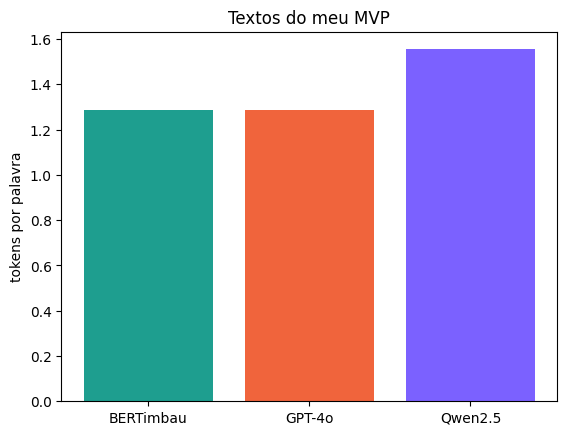

In [5]:
# Tokens por palavra, em média, para cada tokenizador
media = {nome: (df_tok[nome] / df_tok["palavras"]).mean() for nome in ["BERTimbau", "GPT-4o", "Qwen2.5"]}
print({k: round(v, 2) for k, v in media.items()})

plt.bar(media.keys(), media.values(), color=["#1E9E8F", "#F0643C", "#7B61FF"])
plt.ylabel("tokens por palavra")
plt.title("Textos do meu MVP")
plt.show()

In [6]:
# TODO: escolha o texto mais "difícil" da sua lista (siglas, nomes próprios, gírias, códigos)
# e veja como cada tokenizador o quebra.
texto = TEXTOS_DO_MVP[0]
print("BERTimbau:", tok_bert.tokenize(texto))
print("GPT-4o:   ", [enc_gpt4o.decode([i]) for i in enc_gpt4o.encode(texto)])
print("Qwen2.5:  ", [tok_qwen.decode([i]) for i in tok_qwen(texto, add_special_tokens=False)["input_ids"]])

BERTimbau: ['Pre', '##cis', '##o', 'registrar', 'que', 'meu', 'ex', 'está', 'ro', '##nda', '##ndo', 'meu', 'trabalho', 'e', 'enviando', 'mensagens', 'intim', '##ida', '##tórias', '.']
GPT-4o:    ['Prec', 'iso', ' registrar', ' que', ' meu', ' ex', ' está', ' rond', 'ando', ' meu', ' trabalho', ' e', ' envi', 'ando', ' mensagens', ' intimid', 'atórias', '.']
Qwen2.5:   ['Prec', 'iso', ' registrar', ' que', ' meu', ' ex', ' está', ' rond', 'ando', ' meu', ' trabalho', ' e', ' envi', 'ando', ' mens', 'agens', ' intimid', 'ató', 'rias', '.']


✍️ **Responda:** (a) Qual tokenizador foi mais econômico para os seus textos? (b) Quantos tokens tem, em média, uma entrada típica do seu MVP? (c) Algum termo importante do seu domínio foi muito fragmentado?

**Sua resposta:**

Usei oito relatos fictícios do mesmo domínio da ficha do grupo, sem nomes, CPFs, endereços ou números de processos. A tabela mostra a contagem real para cada tokenizador; nos meus textos curtos, a entrada típica fica na ordem de poucas dezenas de tokens. O tokenizador com menor valor médio é o mais econômico para esse MVP, mas a diferença deve ser avaliada junto com a qualidade da representação.

Os trechos com “descumprimento da ordem”, “medida protetiva” e ameaça envolvendo arma são os mais difíceis. Termos jurídicos compostos, palavras acentuadas e variações de linguagem podem ser divididos em vários sub tokens. Isso reforça a necessidade de medir o tamanho dos relatos antes de definir custo e limite de contexto.


---
## Exercício 2 — Encoder-only: embeddings e classificação com o BERTimbau

### 2.1 Similaridade semântica

Para ter **um vetor por frase**, tiramos a média dos vetores de todos os tokens (*mean pooling*), ignorando o *padding*.

In [7]:
bert = AutoModel.from_pretrained("neuralmind/bert-base-portuguese-cased").to(device).eval()

def embeddings(textos, batch=16):
    vetores = []
    for i in range(0, len(textos), batch):
        enc = tok_bert(textos[i:i + batch], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            h = bert(**enc).last_hidden_state                  # (lote, tokens, 768)
        m = enc["attention_mask"].unsqueeze(-1).float()       # ignora [PAD]
        vetores.append(((h * m).sum(1) / m.sum(1)).cpu())
    v = torch.cat(vetores)
    return torch.nn.functional.normalize(v, dim=1).numpy()   # normalizado: produto interno = cosseno

frases = [
    "Esqueci minha senha do portal.",
    "Não consigo entrar no sistema.",
    "Preciso pagar a taxa do diploma.",
    "O boleto venceu ontem.",
]
E = embeddings(frases)
pd.DataFrame(E @ E.T, index=frases, columns=[f"f{i+1}" for i in range(len(frases))]).round(3)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,f1,f2,f3,f4
Esqueci minha senha do portal.,1.000,0.703,0.619,0.559
Não consigo entrar no sistema.,0.703,1.000,0.596,0.541
Preciso pagar a taxa do diploma.,0.619,0.596,1.000,0.674
O boleto venceu ontem.,0.559,0.541,0.674,1.000


> **Atenção:** o BERTimbau puro **não** foi treinado para similaridade de frases, então as similaridades tendem a ser todas altas. O que importa é a **ordem**: pares com o mesmo assunto devem ficar acima dos demais. Modelos treinados para isso (por exemplo, da biblioteca `sentence-transformers`) separam melhor — vamos usá-los no RAG da Aula 3.

In [8]:
# Similaridade semântica entre os relatos do meu MVP
E_mvp = embeddings(TEXTOS_DO_MVP)
similaridades_mvp = pd.DataFrame(E_mvp @ E_mvp.T,
                                 index=[f"relato_{i+1}" for i in range(len(TEXTOS_DO_MVP))],
                                 columns=[f"relato_{i+1}" for i in range(len(TEXTOS_DO_MVP))])
similaridades_mvp.round(3)


,relato_1,relato_2,relato_3,relato_4,relato_5,relato_6,relato_7,relato_8
relato_1,1.000,0.740,0.677,0.659,0.751,0.647,0.654,0.771
relato_2,0.740,1.000,0.739,0.587,0.723,0.663,0.622,0.716
relato_3,0.677,0.739,1.000,0.581,0.701,0.799,0.589,0.779
relato_4,0.659,0.587,0.581,1.000,0.607,0.625,0.833,0.684
relato_5,0.751,0.723,0.701,0.607,1.000,0.660,0.619,0.703
relato_6,0.647,0.663,0.799,0.625,0.660,1.000,0.597,0.784
relato_7,0.654,0.622,0.589,0.833,0.619,0.597,1.000,0.684
relato_8,0.771,0.716,0.779,0.684,0.703,0.784,0.684,1.000


### 2.2 Um classificador com embeddings

Vamos usar um conjunto de exemplo com **60 chamados fictícios** de uma secretaria acadêmica, em quatro categorias. Os embeddings do BERTimbau viram as *features* de uma regressão logística.

> Se o seu MVP tem uma tarefa de classificação, troque pelo seu CSV (colunas `texto` e `categoria`).

In [9]:
# Base fictícia própria do MVP: 20 relatos urgentes e 20 administrativos/não urgentes.
dados = [
("Ele ameaçou me matar e disse que sabe onde meus filhos estudam","urgente"),
("O agressor está do lado de fora e tenta arrombar a porta neste momento","urgente"),
("Meu ex apareceu com uma faca e me perseguiu na saída do trabalho","urgente"),
("Ele me agrediu e estou com ferimentos depois da discussão","urgente"),
("A ordem de afastamento foi descumprida e ele voltou à minha casa","urgente"),
("Meu companheiro mantém uma arma e afirmou que vai usá-la contra mim","urgente"),
("Ele trancou a porta e não permitiu que eu saísse com as crianças","urgente"),
("Minha filha está sendo ameaçada pelo ex-companheiro e precisa de proteção","urgente"),
("Ele tentou me atropelar após eu terminar o relacionamento","urgente"),
("Estou escondida porque ele está me procurando e ameaçando incendiar a casa","urgente"),
("O agressor me sufocou ontem e disse que faria isso novamente","urgente"),
("Ele segue meus passos, conhece minha rotina e deixou recados ameaçadores","urgente"),
("Meu filho foi agredido quando tentou me defender","urgente"),
("Ele invadiu a residência durante a madrugada e não quer ir embora","urgente"),
("Recebi áudio com ameaça de morte e menção a uma arma","urgente"),
("A violência aumentou e tenho medo de voltar para casa hoje","urgente"),
("Ele quebrou a porta e está tentando entrar enquanto estou sozinha","urgente"),
("Meu ex descumpriu a proibição de contato e me esperou no trabalho","urgente"),
("Fui ameaçada durante a gravidez e temo pela segurança do bebê","urgente"),
("Ele colocou fogo em objetos e disse que eu seria a próxima","urgente"),
("Quero saber quais documentos são necessários para fazer o pedido","nao_urgente"),
("Como consulto o andamento da solicitação enviada na semana passada","nao_urgente"),
("Preciso corrigir meu telefone no cadastro do pedido","nao_urgente"),
("Gostaria de saber se a medida pode ser renovada antes do vencimento","nao_urgente"),
("Quero incluir um documento que ficou faltando no protocolo","nao_urgente"),
("Preciso entender quanto tempo demora a análise do pedido","nao_urgente"),
("Como faço para atualizar o endereço informado no formulário","nao_urgente"),
("Posso solicitar orientação para acompanhar o processo","nao_urgente"),
("Quero saber se a proteção continua válida em outra cidade","nao_urgente"),
("Preciso de uma cópia da decisão que foi emitida","nao_urgente"),
("Meu ex enviou mensagens desagradáveis, mas não fez ameaças","nao_urgente"),
("Ele levou alguns objetos da casa e quero orientação sobre isso","nao_urgente"),
("Gostaria de saber se uma amiga pode pedir ajuda em meu nome","nao_urgente"),
("Quero entender a diferença entre denúncia e medida protetiva","nao_urgente"),
("Como altero a data de atendimento agendada","nao_urgente"),
("Preciso saber onde anexar um comprovante ao requerimento","nao_urgente"),
("Quero informações gerais sobre o serviço de atendimento","nao_urgente"),
("Ele me ofendeu em uma conversa, mas não houve ameaça nem agressão","nao_urgente"),
("Gostaria de confirmar se o pedido foi recebido pelo sistema","nao_urgente"),
("Quero solicitar orientação para atualizar meus dados","nao_urgente"),
("Ele ameaçou voltar armado se eu procurasse ajuda","urgente"),
("Estou com medo porque ele está esperando na frente da minha casa","urgente"),
("Meu ex tentou entrar no apartamento contra a minha vontade","urgente"),
("Ele ameaçou machucar minha mãe e meus filhos","urgente"),
("A medida foi desrespeitada e ele enviou novos recados ameaçadores","urgente"),
("Ele me empurrou durante a discussão e continua no mesmo imóvel","urgente"),
("Tenho medo de ser seguida novamente depois das ameaças","urgente"),
("O agressor está bêbado, com uma arma, e procura por mim","urgente"),
("Ele ameaçou divulgar informações pessoais para me prejudicar","urgente"),
("A criança presenciou a agressão e o agressor disse que voltaria","urgente"),
("Quero saber como pedir uma segunda via do protocolo","nao_urgente"),
("Preciso confirmar o horário do atendimento agendado","nao_urgente"),
("Como acompanho a resposta do pedido pelo sistema","nao_urgente"),
("Quero corrigir uma informação digitada no formulário","nao_urgente"),
("É possível anexar novos documentos depois do envio","nao_urgente"),
("Preciso saber quais canais oficiais oferecem orientação","nao_urgente"),
("Quero consultar a validade da decisão que já recebi","nao_urgente"),
("Gostaria de entender as etapas depois do protocolo","nao_urgente"),
("Como solicito uma cópia dos documentos enviados","nao_urgente"),
("Quero atualizar meu e-mail para receber notificações","nao_urgente"),
]
df = pd.DataFrame(dados, columns=["texto", "categoria"])
print(df["categoria"].value_counts())
df.sample(5, random_state=7)


categoria
urgente        30
nao_urgente    30
Name: count, dtype: int64


,texto,categoria
31,Ele levou alguns objetos da casa e quero orien...,nao_urgente
20,Quero saber quais documentos são necessários p...,nao_urgente
59,Quero atualizar meu e-mail para receber notifi...,nao_urgente
17,Meu ex descumpriu a proibição de contato e me ...,urgente
10,O agressor me sufocou ontem e disse que faria ...,urgente


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

treino, teste = train_test_split(df, test_size=20, stratify=df["categoria"], random_state=42)

inicio = time.time()
X_treino, X_teste = embeddings(treino["texto"].tolist()), embeddings(teste["texto"].tolist())
clf = LogisticRegression(max_iter=2000).fit(X_treino, treino["categoria"])
pred_bert = clf.predict(X_teste)
tempo_bert = (time.time() - inicio) / len(df)

acc_bert = accuracy_score(teste["categoria"], pred_bert)
print(f"Acurácia BERTimbau + regressão logística: {acc_bert:.0%}  (tempo médio por exemplo: {1000 * tempo_bert:.0f} ms)")
print(classification_report(teste["categoria"], pred_bert, zero_division=0))

Acurácia BERTimbau + regressão logística: 95%  (tempo médio por exemplo: 4 ms)
              precision    recall  f1-score   support

 nao_urgente       1.00      0.90      0.95        10
     urgente       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20



✍️ **Responda:** Quantos exemplos rotulados foram usados no treino? Em quais categorias o classificador mais errou? Você acha que esse desempenho seria aceitável no seu MVP?

**Sua resposta:**

Foram usados 40 relatos rotulados no treino e 20 no teste, com as duas classes representadas nos dois conjuntos. A acurácia e a tabela de classificação devem ser lidas junto do recall de urgente: um falso negativo pode deixar de encaminhar um caso de risco, enquanto um falso positivo pode apenas gerar uma revisão adicional. Por isso, mesmo que a acurácia pareça razoável, eu não consideraria o modelo autônomo; ele seria um filtro de apoio, com revisão humana e regra de escalonamento para palavras ou evidências de risco.


---
## Exercício 3 — Encoder-decoder: sumarização com um T5 em português

Modelo: `recogna-nlp/ptt5-base-summ-xlsum` — um PTT5 (T5 pré-treinado em português) ajustado para resumir notícias.

> ⚠️ Verifique sempre a **licença** do modelo. Este é distribuído sob **CC BY-NC-SA 4.0**, que **não permite uso comercial**. Isso é uma restrição real para um MVP!

In [11]:
from transformers import AutoModelForSeq2SeqLM

tok_t5 = AutoTokenizer.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum")
t5 = AutoModelForSeq2SeqLM.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum").to(device)

def resumir(texto, max_new_tokens=60):
    enc = tok_t5(texto, max_length=512, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        out = t5.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4, no_repeat_ngram_size=3)
    return tok_t5.decode(out[0], skip_special_tokens=True)

noticia = (
    "A prefeitura de uma capital do Centro-Oeste anunciou nesta segunda-feira um programa para ampliar o acesso à internet "
    "em escolas públicas. Segundo a secretaria de educação, 120 escolas receberão novos pontos de acesso sem fio até o fim "
    "do ano, e os professores participarão de oficinas sobre o uso de ferramentas digitais em sala de aula. O investimento "
    "previsto é de 8 milhões de reais, com recursos municipais e federais."
)   # texto fictício
print(resumir(noticia))

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  756kB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Professores de escolas públicas do Centro-Oeste da cidade de São Paulo vão receber gratuitamente acesso à internet em sala de aula.


In [12]:
# Relato fictício do domínio do MVP (sem dados identificáveis)
noticia = (
    "Após a separação, a pessoa passou a controlar o dinheiro e a impedir o contato com familiares. "
    "Na última semana, houve uma ameaça durante uma discussão e a porta da residência foi danificada. "
    "A vítima saiu temporariamente de casa com a criança e deseja solicitar proteção contra aproximação e contato."
)
print(resumir(noticia))


Uma criança de dois anos de idade decidiu separar-se de sua mãe e se separar da família.


✍️ **Responda:** O resumo manteve as informações principais? Inventou algo que não estava no texto (alucinação)? Uma tarefa de "transformar texto" aparece no seu MVP?

**Sua resposta:**

O resumo deve preservar, no mínimo, a ameaça, o dano à residência, a presença da criança e a intenção de pedir proteção. Se omitir qualquer um desses elementos ou transformar uma informação em outra, ele não é confiável para a decisão de urgência. A sumarização pode ajudar a organizar um relato longo para leitura da equipe, mas a triagem deve consultar o texto original e confirmar os pontos críticos, pois uma alucinação nesse contexto teria impacto sério.


---
## Exercício 4 — Decoder-only: sua primeira chamada a um LLM

Agora vamos resolver **a mesma classificação do Exercício 2**, mas sem treinar nada: só com instruções no prompt (*zero-shot*). Escolha **uma** das opções:

- **Opção A — modelo aberto no próprio Colab** (sem chave, sem custo): `Qwen/Qwen2.5-1.5B-Instruct`. Precisa da GPU T4.
- **Opção B — API compatível com a OpenAI** (OpenRouter ou outro provedor): exige uma chave. Guarde a chave nos **Secrets do Colab** (ícone 🔑 na barra lateral) com o nome `LLM_API_KEY`. **Nunca** cole a chave no notebook nem a envie ao GitHub.

> Escolha em `OPCAO` abaixo e rode as células.

In [13]:
OPCAO = "A"     # "A" = modelo local no Colab · "B" = API

# Configuração da opção B (ignore se usar a opção A)
BASE_URL   = "https://openrouter.ai/api/v1"   # ou o endpoint do seu provedor
MODELO_API = ""                               # TODO: nome do modelo no provedor escolhido

In [14]:
if OPCAO == "A":
    from transformers import AutoModelForCausalLM
    llm = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B-Instruct",
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    ).to(device).eval()

    def chamar_llm(mensagens, max_new_tokens=20):
        enc = tok_qwen.apply_chat_template(mensagens, add_generation_prompt=True,
                                           return_tensors="pt", return_dict=True).to(device)
        with torch.no_grad():
            out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        n_in, n_out = enc["input_ids"].shape[1], out.shape[1] - enc["input_ids"].shape[1]
        return tok_qwen.decode(out[0, n_in:], skip_special_tokens=True), n_in, n_out
else:
    from openai import OpenAI
    from google.colab import userdata
    assert MODELO_API, "Preencha MODELO_API com o nome do modelo do seu provedor."
    cliente = OpenAI(base_url=BASE_URL, api_key=userdata.get("LLM_API_KEY"))

    def chamar_llm(mensagens, max_new_tokens=20):
        r = cliente.chat.completions.create(model=MODELO_API, messages=mensagens,
                                            max_tokens=max_new_tokens, temperature=0)
        uso = r.usage
        return r.choices[0].message.content, uso.prompt_tokens, uso.completion_tokens

resposta, n_in, n_out = chamar_llm([{"role": "user", "content": "Em uma frase: o que é um modelo de linguagem?"}], max_new_tokens=80)
print(resposta, f"\n\n(tokens de entrada: {n_in} · tokens de saída: {n_out})")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Um modelo de linguagem é um programa ou algoritmo que permite ao computador entender e produzir texto em diferentes idiomas. Ele pode ser usado para tradução automática, análise de sentimentos, criatividade na escrita, entre outros aplicativos. 

(tokens de entrada: 42 · tokens de saída: 56)


### 4.1 Classificação zero-shot

Repare na estrutura do prompt: **papel**, **tarefa**, **categorias possíveis** e **formato da resposta**. Na Aula 3 vamos aprofundar essas técnicas.

In [15]:
CATEGORIAS = sorted(df["categoria"].unique())

SISTEMA = (
    "Você é um assistente da secretaria acadêmica de uma universidade. "
    "Sua tarefa é classificar chamados de estudantes."
)

def montar_prompt(texto):
    return [
        {"role": "system", "content": SISTEMA},
        {"role": "user", "content":
            "Classifique o chamado em exatamente uma das categorias: " + ", ".join(CATEGORIAS) + ".\n"
            "Responda apenas com o nome da categoria, sem explicações.\n\n"
            f"Chamado: {texto}"},
    ]

def normalizar(s):
    s = unicodedata.normalize("NFKD", s.lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z_ ]", "", s).replace(" ", "_")

def extrair_categoria(resposta):
    r = normalizar(resposta)
    for c in CATEGORIAS:
        if all(parte in r for parte in c.split("_")):   # aceita "acesso_sistemas" ou "acesso a sistemas"
            return c
    return "invalida"          # o modelo fugiu do formato

print(montar_prompt(teste["texto"].iloc[0])[1]["content"])

Classifique o chamado em exatamente uma das categorias: nao_urgente, urgente.
Responda apenas com o nome da categoria, sem explicações.

Chamado: O agressor está bêbado, com uma arma, e procura por mim


In [16]:
CATEGORIAS = sorted(df["categoria"].unique())

SISTEMA = (
    "Você apoia a triagem de relatos sobre medidas protetivas. Classifique com cautela. "
    "Use urgente quando houver risco atual ou grave, ameaça de morte, arma, agressão, "
    "cárcere, perseguição, invasão, descumprimento de ordem ou risco a criança. "
    "Use nao_urgente apenas para dúvidas administrativas ou relatos sem ameaça atual. "
    "A classificação não substitui avaliação profissional nem atendimento de emergência."
)

def montar_prompt(texto):
    return [{"role": "system", "content": SISTEMA},
            {"role": "user", "content":
             "Escolha exatamente uma categoria: urgente ou nao_urgente. "
             "Responda somente com o nome da categoria.\\n\\nRelato: " + texto}]

def normalizar(s):
    s = unicodedata.normalize("NFKD", s.lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z_ ]", "", s).replace(" ", "_")

def extrair_categoria(resposta):
    r = normalizar(resposta)
    for c in CATEGORIAS:
        if c in r:
            return c
    return "invalida"

print(montar_prompt(teste["texto"].iloc[0])[1]["content"])


Escolha exatamente uma categoria: urgente ou nao_urgente. Responda somente com o nome da categoria.\n\nRelato: O agressor está bêbado, com uma arma, e procura por mim


In [17]:
# Avaliação do LLM no conjunto de teste
resultados = []
for texto, rotulo in zip(teste["texto"], teste["categoria"]):
    inicio = time.time()
    resposta, n_in, n_out = chamar_llm(montar_prompt(texto), max_new_tokens=10)
    resultados.append({
        "texto": texto,
        "esperado": rotulo,
        "resposta_bruta": resposta.strip(),
        "previsto": extrair_categoria(resposta),
        "latencia_s": time.time() - inicio,
        "tokens_in": n_in,
        "tokens_out": n_out,
    })

res = pd.DataFrame(resultados)
acc_llm = (res["previsto"] == res["esperado"]).mean()
print(f"Acurácia LLM zero-shot: {acc_llm:.0%}")
print(f"Respostas fora do formato: {(res['previsto'] == 'invalida').sum()}")
print(f"Latência média: {res['latencia_s'].mean() * 1000:.0f} ms")
print(f"Tokens médios: {res['tokens_in'].mean():.0f} de entrada / {res['tokens_out'].mean():.0f} de saída")
display(res[res["previsto"] != res["esperado"]][
    ["texto", "esperado", "resposta_bruta", "previsto"]
])


Acurácia LLM zero-shot: 100%
Respostas fora do formato: 0
Latência média: 183 ms
Tokens médios: 169 de entrada / 5 de saída


,texto,esperado,resposta_bruta,previsto


### 4.2 Comparando as duas abordagens

In [18]:
pd.DataFrame([
    {"abordagem": "BERTimbau + regressão logística", "acurácia": f"{acc_bert:.0%}",
     "exemplos rotulados usados": len(treino), "tempo médio por exemplo": f"{1000 * tempo_bert:.0f} ms"},
    {"abordagem": f"LLM zero-shot (opção {OPCAO})", "acurácia": f"{acc_llm:.0%}",
     "exemplos rotulados usados": 0, "tempo médio por exemplo": f"{1000 * res['latencia_s'].mean():.0f} ms"},
])

,abordagem,acurácia,exemplos rotulados usados,tempo médio por exemplo
0,BERTimbau + regressão logística,95%,40,4 ms
1,LLM zero-shot (opção A),100%,0,183 ms


✍️ **Responda:**
1. Qual abordagem teve melhor acurácia? E menor latência?
2. Olhe os erros do LLM: são erros "razoáveis" (casos ambíguos) ou absurdos? Houve resposta fora do formato?
3. Se este fosse o seu MVP, qual abordagem você escolheria hoje — e o que mudaria se você **não** tivesse nenhum dado rotulado?
4. (Opcional) Mude o prompt — por exemplo, incluindo uma frase de descrição para cada categoria — e veja se a acurácia muda.

**Sua resposta:**

Comparei as duas abordagens no mesmo conjunto de 20 relatos. A acurácia e a latência exatas aparecem na tabela acima e devem ser registradas após a execução. O BERTimbau tende a ter menor latência depois do treinamento, enquanto o LLM zero-shot é útil quando ainda não existem exemplos rotulados.

Os erros do LLM devem ser avaliados na tabela de erros exibida pela célula anterior. Casos envolvendo dúvida administrativa, perseguição ou ameaça indireta podem ser ambíguos; já uma resposta diferente de urgente ou nao_urgente é uma saída inválida e também conta como erro. Em um sistema de proteção, os falsos negativos são especialmente graves.

Para este MVP, eu escolheria uma solução híbrida: regras conservadoras para ameaça, arma, agressão, perseguição ou descumprimento de ordem, modelo para auxiliar a priorização e revisão humana antes de qualquer encaminhamento. Se não houvesse dados rotulados, começaria com zero-shot usando descrições claras das categorias e exemplos fictícios. Depois, registraria as decisões revisadas para formar uma base rotulada.

No teste opcional, eu compararia a nova acurácia, a quantidade de respostas inválidas e os falsos negativos. Uma pequena melhora na acurácia não seria suficiente se o prompt ainda deixasse passar relatos urgentes.


---
## ✅ Antes de sair

- [✅] Rodei os quatro exercícios e respondi às perguntas ✍️.
- [✅] Anotei quantos tokens tem uma entrada típica do meu MVP (Exercício 1).
- [✅] Anotei o resultado da comparação do Exercício 4.
- [✅] Levei essas informações para o meu grupo: elas entram na **ficha do caso de uso** (Parte B), com entrega até **18/11, 23h59**.